In [2]:
pip install pymoo matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 59.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 32.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


Amostra de 5 solucoes inteiras encontradas (Pods, Analistas):
Pods: 30 | Analistas: 15 => Latencia:  23.33ms | Custo: R$ 1215.00
Pods:  1 | Analistas:  1 => Latencia: 550.00ms | Custo: R$  63.00
Pods:  2 | Analistas:  1 => Latencia: 350.00ms | Custo: R$  81.00
Pods:  3 | Analistas:  1 => Latencia: 283.33ms | Custo: R$  99.00
Pods:  4 | Analistas:  1 => Latencia: 250.00ms | Custo: R$ 117.00


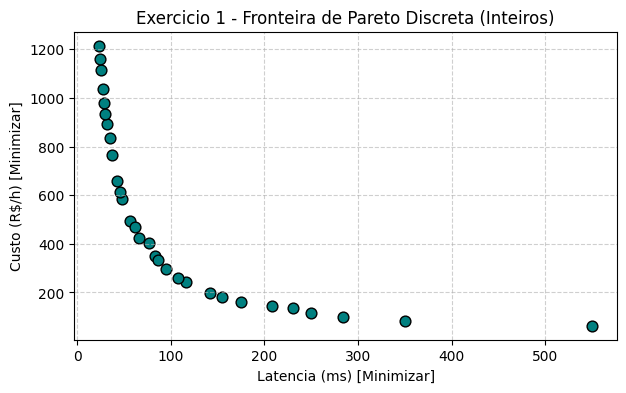

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.sampling.rnd import IntegerRandomSampling
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.operators.repair.rounding import RoundingRepair
from pymoo.optimize import minimize

class SOCInteiroProblem(ElementwiseProblem):
    def __init__(self):
        # x1: Pods (1 a 30), x2: Analistas de Nivel 2 (1 a 15) -> Ambos inteiros!
        super().__init__(
            n_var=2,
            n_obj=2,
            xl=np.array([1, 1]),
            xu=np.array([30, 15]),
            vtype=int
        )

    def _evaluate(self, x, out, *args, **kwargs):
        pods, analistas = x[0], x[1]
        f1_latencia = (400.0 / pods) + (150.0 / analistas)
        f2_custo = (pods * 18.0) + (analistas * 45.0)
        out["F"] = [f1_latencia, f2_custo]

algorithm = NSGA2(
    pop_size=30,
    sampling=IntegerRandomSampling(),
    crossover=SBX(prob=0.9, eta=15, vtype=float, repair=RoundingRepair()),
    mutation=PM(prob=0.2, eta=20, vtype=float, repair=RoundingRepair()),
    eliminate_duplicates=True
)

res1 = minimize(SOCInteiroProblem(), algorithm, termination=('n_gen', 40), seed=42)

print("Amostra de 5 solucoes inteiras encontradas (Pods, Analistas):")
for sol_x, sol_f in zip(res1.X[:5], res1.F[:5]):
    print(f"Pods: {sol_x[0]:2d} | Analistas: {sol_x[1]:2d} => Latencia: {sol_f[0]:6.2f}ms | Custo: R$ {sol_f[1]:6.2f}")

plt.figure(figsize=(7, 4))
plt.scatter(res1.F[:, 0], res1.F[:, 1], color='teal', s=60, edgecolor='black')
plt.title("Exercicio 1 - Fronteira de Pareto Discreta (Inteiros)")
plt.xlabel("Latencia (ms) [Minimizar]")
plt.ylabel("Custo (R$/h) [Minimizar]")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [4]:
import numpy as np
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.sampling.rnd import IntegerRandomSampling
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.operators.repair.rounding import RoundingRepair
from pymoo.optimize import minimize

class KubernetesClusterProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(
            n_var=2,
            n_obj=2,
            xl=np.array([2, 1]),
            xu=np.array([40, 12]),
            vtype=int
        )

    def _evaluate(self, x, out, *args, **kwargs):
        replicas, nodes = x[0], x[1]

        # TODO 1 e 2 Resolvidos
        f1_tempo = (600.0 / replicas) + (200.0 / nodes)
        f2_custo = (replicas * 12.0) + (nodes * 85.0)

        out["F"] = [f1_tempo, f2_custo]

# TODO 3 Resolvido
algorithm = NSGA2(
    pop_size=25,
    sampling=IntegerRandomSampling(),
    crossover=SBX(prob=0.9, eta=15, vtype=float, repair=RoundingRepair()),
    mutation=PM(prob=0.2, eta=20, vtype=float, repair=RoundingRepair()),
    eliminate_duplicates=True
)

# TODO 4 Resolvido
res2 = minimize(KubernetesClusterProblem(), algorithm, termination=('n_gen', 35), seed=10)

print("Amostra de 5 solucoes encontradas (Replicas, Nodes):")
for sol_x, sol_f in zip(res2.X[:5], res2.F[:5]):
    print(f"Replicas: {sol_x[0]:2d} | Nodes: {sol_x[1]:2d} => Tempo: {sol_f[0]:6.2f}ms | Custo: USD {sol_f[1]:6.2f}")

Amostra de 5 solucoes encontradas (Replicas, Nodes):
Replicas:  2 | Nodes:  1 => Tempo: 500.00ms | Custo: USD 109.00
Replicas: 40 | Nodes: 12 => Tempo:  31.67ms | Custo: USD 1500.00
Replicas:  3 | Nodes:  1 => Tempo: 400.00ms | Custo: USD 121.00
Replicas:  4 | Nodes:  1 => Tempo: 350.00ms | Custo: USD 133.00
Replicas: 33 | Nodes:  8 => Tempo:  43.18ms | Custo: USD 1076.00


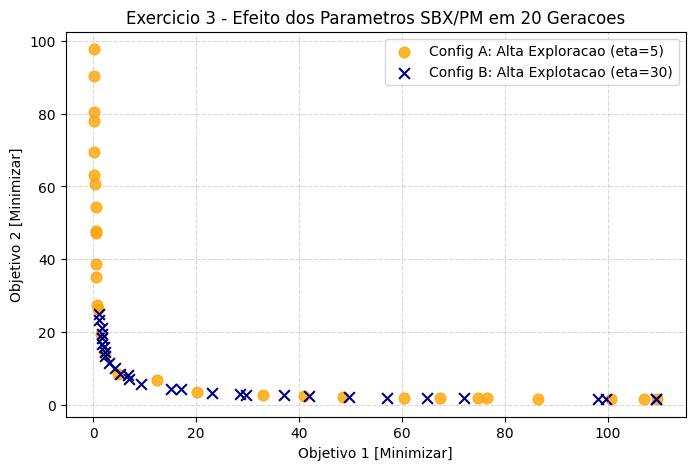

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.optimize import minimize

class BenchmarkTradeoffProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=2, n_obj=2, xl=np.array([0.1, 0.1]), xu=np.array([10.0, 10.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        f1 = x[0]**2 + x[1]
        f2 = (10.0 / x[0]) + (5.0 / x[1])
        out["F"] = [f1, f2]

problem = BenchmarkTradeoffProblem()

alg_exploracao = NSGA2(
    pop_size=30,
    crossover=SBX(prob=0.9, eta=5),
    mutation=PM(prob=0.5, eta=5)
)

alg_explotacao = NSGA2(
    pop_size=30,
    crossover=SBX(prob=0.9, eta=30),
    mutation=PM(prob=0.05, eta=30)
)

res_a = minimize(problem, alg_exploracao, ('n_gen', 20), seed=42)
res_b = minimize(problem, alg_explotacao, ('n_gen', 20), seed=42)

plt.figure(figsize=(8, 5))
plt.scatter(res_a.F[:, 0], res_a.F[:, 1], color='orange', label='Config A: Alta Exploracao (eta=5)', alpha=0.8, s=60)
plt.scatter(res_b.F[:, 0], res_b.F[:, 1], color='navy', marker='x', label='Config B: Alta Explotacao (eta=30)', s=60)
plt.title("Exercicio 3 - Efeito dos Parametros SBX/PM em 20 Geracoes")
plt.xlabel("Objetivo 1 [Minimizar]")
plt.ylabel("Objetivo 2 [Minimizar]")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [6]:
import numpy as np
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.indicators.hv import HV

class RedeSensoresProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=2, n_obj=2, xl=np.array([1.0, 1.0]), xu=np.array([100.0, 60.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        potencia, intervalo = x[0], x[1]
        f1_consumo_bateria = (potencia * 2.5) + (120.0 / intervalo)
        f2_perda_pacotes = (500.0 / potencia) + (intervalo * 0.8)
        out["F"] = [f1_consumo_bateria, f2_perda_pacotes]

problem = RedeSensoresProblem()

# TODO 1 e 2 Resolvidos
res_curto = minimize(problem, NSGA2(pop_size=40), termination=('n_gen', 10), seed=42)
res_longo = minimize(problem, NSGA2(pop_size=40), termination=('n_gen', 80), seed=42)

ref_point = np.array([400.0, 600.0])
metrica_hv = HV(ref_point=ref_point)

# TODO 3 Resolvido
hv_10_gen = metrica_hv(res_curto.F)
hv_80_gen = metrica_hv(res_longo.F)

print(f"Hipervolume (10 geracoes): {hv_10_gen}")
print(f"Hipervolume (80 geracoes): {hv_80_gen}")

Hipervolume (10 geracoes): 226626.7047731528
Hipervolume (80 geracoes): 226715.93778257925


Decisao Recomendada (Pesos 30% Custo / 70% Performance):
-> Configuracao: 76.6 GB RAM | 2755 IOPS
-> Resultado:    US$ 56.52/h | Tempo de Query: 8.06 ms


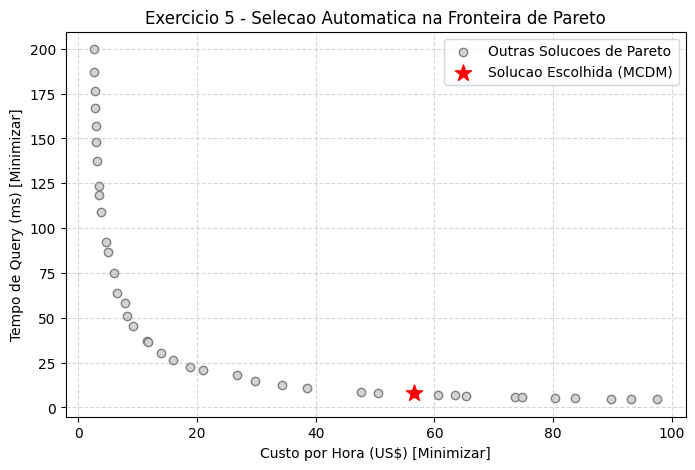

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.mcdm.pseudo_weights import PseudoWeights

class CloudDatabaseProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=2, n_obj=2, xl=np.array([4.0, 100.0]), xu=np.array([128.0, 5000.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        ram, iops = x[0], x[1]
        f1_custo_hora = (ram * 0.45) + (iops * 0.008)
        f2_tempo_query = (200.0 / ram) + (15000.0 / iops)
        out["F"] = [f1_custo_hora, f2_tempo_query]

res5 = minimize(CloudDatabaseProblem(), NSGA2(pop_size=40), ('n_gen', 50), seed=42)

pesos = np.array([0.30, 0.70])
indice_escolhido = PseudoWeights(pesos).do(res5.F)

melhor_x = res5.X[indice_escolhido]
melhor_f = res5.F[indice_escolhido]

print(f"Decisao Recomendada (Pesos 30% Custo / 70% Performance):")
print(f"-> Configuracao: {melhor_x[0]:.1f} GB RAM | {melhor_x[1]:.0f} IOPS")
print(f"-> Resultado:    US$ {melhor_f[0]:.2f}/h | Tempo de Query: {melhor_f[1]:.2f} ms")

plt.figure(figsize=(8, 5))
plt.scatter(res5.F[:, 0], res5.F[:, 1], color='lightgray', edgecolor='gray', label='Outras Solucoes de Pareto')
plt.scatter(melhor_f[0], melhor_f[1], color='red', s=150, marker='*', label='Solucao Escolhida (MCDM)')
plt.title("Exercicio 5 - Selecao Automatica na Fronteira de Pareto")
plt.xlabel("Custo por Hora (US$) [Minimizar]")
plt.ylabel("Tempo de Query (ms) [Minimizar]")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [8]:
import numpy as np
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.sampling.rnd import IntegerRandomSampling
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.operators.repair.rounding import RoundingRepair
from pymoo.optimize import minimize
from pymoo.mcdm.pseudo_weights import PseudoWeights

class EscalaHospitalarProblem(ElementwiseProblem):
    def __init__(self):
        # TODO 1 Resolvido
        super().__init__(
            n_var=2,
            n_obj=2,
            n_ieq_constr=1,
            xl=np.array([2, 4]),
            xu=np.array([20, 40]),
            vtype=int
        )

    def _evaluate(self, x, out, *args, **kwargs):
        medicos, enfermeiros = x[0], x[1]

        f1_custo = (medicos * 1200.0) + (enfermeiros * 450.0)
        f2_espera = (180.0 / medicos) + (240.0 / enfermeiros)

        # TODO 2 Resolvido (G(x) <= 0)
        g1 = f2_espera - 25.0

        out["F"] = [f1_custo, f2_espera]
        out["G"] = [g1]

# TODO 3 Resolvido
algorithm = NSGA2(
    pop_size=40,
    sampling=IntegerRandomSampling(),
    crossover=SBX(prob=0.9, eta=15, vtype=float, repair=RoundingRepair()),
    mutation=PM(prob=0.2, eta=20, vtype=float, repair=RoundingRepair()),
    eliminate_duplicates=True
)

res6 = minimize(EscalaHospitalarProblem(), algorithm, termination=('n_gen', 50), seed=42)

# TODO 4 Resolvido
pesos = np.array([0.40, 0.60])
indice_escolhido = PseudoWeights(pesos).do(res6.F)

melhor_x = res6.X[indice_escolhido]
melhor_f = res6.F[indice_escolhido]

print("Escala Recomendada (MCDM - 40% Custo, 60% Espera):")
print(f"-> {melhor_x[0]} Medicos | {melhor_x[1]} Enfermeiros")
print(f"-> Custo: R$ {melhor_f[0]:.2f} | Tempo Espera: {melhor_f[1]:.2f} min")

Escala Recomendada (MCDM - 40% Custo, 60% Espera):
-> 17 Medicos | 32 Enfermeiros
-> Custo: R$ 34800.00 | Tempo Espera: 18.09 min
